# 2. Симуляции в Python

In [1]:
import matplotlib.pyplot as plt
import numpy as np
from scipy import stats

## Задание 2.1. Нормальная выборка

● сгенерировать 5000 значений нормального распределения, например со средним 40 и
стандартным отклонением 8;
● построить гистограмму и нарисовать поверх неё теоретическую плотность;
● сравнить среднее и стандартное отклонение выборки с теми, что вы задали.

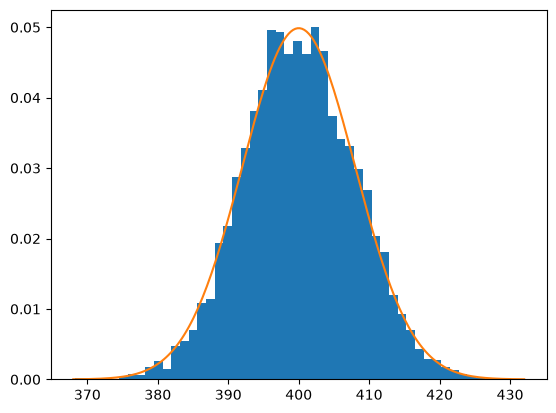

Заданное среднее: 400, среднее выборки: 400.099
Заданное отклонение: 8, отклонение выборки: 7.936


In [2]:
mu, sigma = 400, 8

sample = np.random.normal(mu, sigma, size=5000)

x = np.linspace(mu - 4*sigma, mu + 4*sigma, 200)

plt.hist(sample, bins=50, density=True)
plt.plot(x, stats.norm.pdf(x, mu, sigma))
plt.show()

print(f"Заданное среднее: {mu}, среднее выборки: {sample.mean():.3f}")
print(f"Заданное отклонение: {sigma}, отклонение выборки: {sample.std():.3f}")

Среднее и отклонение выборки стремятся к заданным параметрам.

## Задание 2.2. Биномиальная выборка

● сгенерировать 5000 значений биномиального распределения, например n = 1000, p = 0,04;
● построить гистограмму и нарисовать поверх неё теоретическую функцию вероятности;
● сравнить среднее и стандартное отклонение выборки с теоретическими значениями.

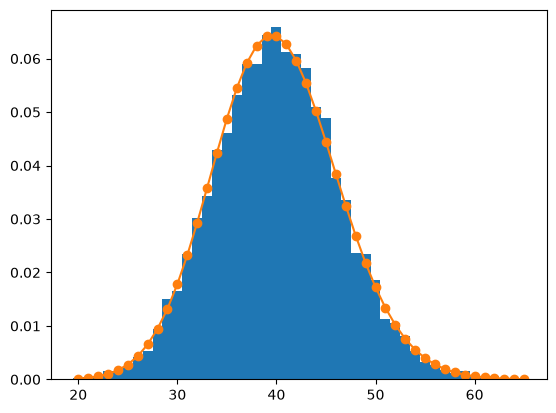

Заданное среднее: 40.0, среднее выборки: 40.074
Заданное отклонение: 6.196773353931867, отклонение выборки: 6.213


In [3]:
n, p = 1000, 0.04
sample = np.random.binomial(n, p, size=5000) # sample[i] это отклики за i-й день
k = np.arange(sample.min(), sample.max() + 1)
plt.hist(sample, bins=k - 0.5, density=True)
plt.plot(k, stats.binom.pmf(k, n, p), 'o-') # теоретическая функция вероятности
plt.show()

print(f"Заданное среднее: {n * p}, среднее выборки: {sample.mean():.3f}")
print(f"Заданное отклонение: {np.sqrt(n * p * (1 - p))}, отклонение выборки: {sample.std():.3f}")

Среднее и отклонение выборки стремятся к заданным параметрам.

## Задание 2.3. ЦПТ на экспоненциальном распределении

● сгенерировать выборку из 500 значений экспоненциального распределения и посчитать её
среднее;
● повторить это несколько тысяч раз;
● построить гистограмму полученных средних и в двух-трёх предложениях описать, что на ней
видно и почему.

1353.089789107183


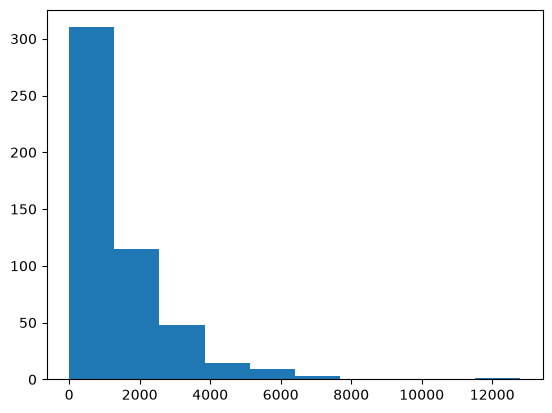

In [4]:
solo = np.random.exponential(scale=1500, size=500)
plt.hist(solo)
print(solo.mean())


Экспоненциальное распределение перекошено вправо

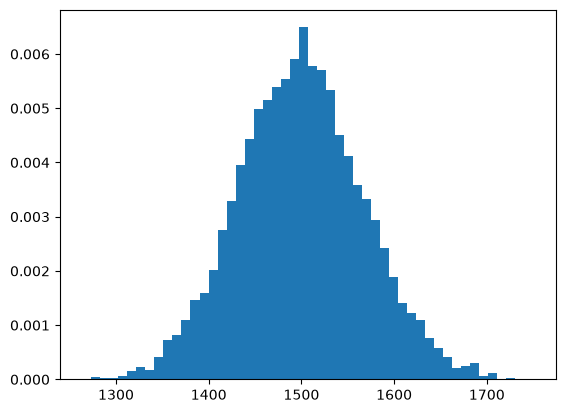

In [5]:
n_per_day = 500 # значений в одной выборке
n_days = 7000 # несколько тысяч раз
daily_means = [
np.random.exponential(scale=1500, size=n_per_day).mean() # среднее
for _ in range(n_days)
]
plt.hist(daily_means, bins=50, density=True)
plt.show()

Мы видим на ней нормальное распределение. Нормальное распределение, потому что мы берем средние по большим выборке, что отсылает нас к ЦПТ.

Центральная предельная теорема: среднее по большой выборке можно считать
нормально распределённой величиной с центром в истинном μ и стандартным отклонением σ/√n,
где σ это стандартное отклонение одного наблюдения, а n размер выборки. Исходное
распределение при этом может быть любым: колокол, перекошенные зарплаты, отклик 0/1.

# 3. Мини-кейс про кнопку

Кнопку «Откликнуться» перекрасили и сравнили две группы соискателей.

```text
Группа         Соискателей  Откликов  Конверсия
Старая кнопка  5000         155       3,1%
Новая кнопка   5000         170       3,4%
```

Разница конверсий 0,3 п.п. Нужно понять, это эффект новой кнопки или случайность.

In [6]:
n_old, p_old = 5000, 0.031
n_new, p_new = 5000, 0.034

## Задание 3.1. Посчитать по формуле

● для каждой группы посчитать, насколько может случайно ошибаться оценка конверсии
(стандартную ошибку);
● сравнить ошибку с разницей 0,3 п.п.;
● написать предварительный вывод

In [7]:
Varx_old = p_old * (1 - p_old)
Varx_old = p_new * (1 - p_new)

se_old = np.sqrt(Varx_old / n_old)
se_new = np.sqrt(Varx_old / n_new)

print(f"Ошибка старой кнопки: {se_old * 100:.3f} п.п.")
print(f"Ошибка новой кнопки: {se_new * 100:.3f} п.п.")

Ошибка старой кнопки: 0.256 п.п.
Ошибка новой кнопки: 0.256 п.п.


Разница конверсий сопоставима с обычным случайным шумом (0.3 п.п. и 0.245 п.п. и 0.256 п.п.). Мы не можем уверенно сказать, что рост в 0,3 п.п. - это эффект от новой кнопки, а не просто случайное колебание метрики. Данных еще недостаточно.

## Задание 3.2. Проверить симуляцией

● предположить, что кнопка ни на что не влияет и конверсия в обеих группах одинаковая;
● много раз смоделировать две такие группы по 5000 соискателей и посчитать разницу их
конверсий;
● построить гистограмму разниц и посчитать, как часто случайно получается 0,3 п.п. или больше;
● ответить: шум это или эффект.

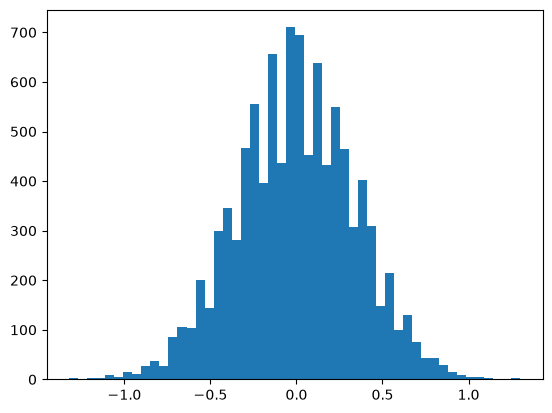

Случайная разница >= 0,3 п.п. получается в 19.960% случаев


In [8]:
n = 5000 # соискателей
p = 0.031  # предполагаем, что новая кнопка не сработала и конверсия везде 3,1%
n_repeats = 10000  # количество симуляций

# моделируем две группы по 5000 соискателей 10000 раз
group_old = np.random.binomial(n, p, size=n_repeats)
group_new = np.random.binomial(n, p, size=n_repeats)

# разница между конверсиями в п.п.
diffs = (group_new - group_old) / n * 100

plt.hist(diffs, bins=50)
plt.show()

gt03pp = (diffs >= 0.3).sum() / n_repeats * 100

print(f"Случайная разница >= 0,3 п.п. получается в {gt03pp:.3f}% случаев")

Мы получили вероятность получения такой же разницы между группами ~= 19.960%. И это по сути p-value. Наше p-value больше, чем уровень значимости alpha, поэтому мы не можем отвернуть нулевую гипотезу.

## Задание 3.3. Выбросы во времени сессий

Время сессий за день, в минутах: 3, 4, 4, 5, 5, 6, 6, 7, 8, 52.
● найти выбросы правилом трёх сигм;
● найти выбросы по перцентилям;
● сравнить результаты и объяснить, какой способ сработал лучше и почему.

In [9]:
x = np.array([3, 4, 4, 5, 5, 6, 6, 7, 8, 52])


# правило трёх сигм
upper_3s = x.mean() + 3 * x.std(ddof=1)
outliers_3s = x[x > upper_3s]

print(f"Граница 3 сигм: {upper_3s:.1f}")
print(f"Выбросы по 3 сигмам: {outliers_3s}")

# перцентили
p25, p75 = np.percentile(x, [25, 75])
upper_pct = p75 + 1.5 * (p75 - p25)
outliers_pct = x[x > upper_pct]

print(f"\nГраница по перцентилям: {upper_pct:.1f}")
print(f"Выбросы по перцентилям: {outliers_pct}")

Граница 3 сигм: 54.5
Выбросы по 3 сигмам: []

Граница по перцентилям: 10.5
Выбросы по перцентилям: [52]


В перцентилях мы рассматриваем межквартильный интервал. Способ с перцентилями справился лучше для нахождения выбросов. Среднее значение уезжает вместе с выбросом, что делает его использование для отбрасывания выбросов на маленьких выборках не очень корректным.